## Fase #5: Evaluación / Evaluation
En esta etapa del proyecto, se ha construido un modelo que parece tener alta calidad desde una perspectiva de análisis de datos. Antes de proceder a la implementación final del modelo, es importante evaluar más a fondo el modelo y revisar los pasos realizados para construir el modelo y asegurarse de que logra correctamente los objetivos definidos en la fase de comprensión del negocio. Un objetivo clave es determinar si hay algún tema importante del negocio que no se haya considerado lo suficiente. Al final de esta fase, se debe tomar una decisión sobre el uso de los resultados de la minería de datos.

### Métricas de evaluación

| Métrica | Interpretación |
|---|---|
| MAE | Error absoluto promedio en m³. Es la métrica principal por su lectura directa. |
| RMSE | Error en m³ que penaliza con mayor fuerza los desaciertos grandes. |
| Error mediano absoluto | Error típico menos sensible a valores extremos. |
| R² | Proporción de variación explicada respecto de predecir la media; puede ser negativa en prueba. |

La matriz de confusión no corresponde porque el problema final es de regresión. Además de las métricas, se revisarán errores por año y gráficos de observado frente a estimado.

In [2]:
# @title Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display  # ty: ignore[unresolved-import]
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score

from comun import importar_modelos, leer_dataframe_con_fechas


In [3]:
# @title Preparación de variables

objetivo = "agua_inyectada_m3"
entradas_numericas = ["longitud_rama_horizontal_m", "cantidad_fracturas"]
entradas_categoricas = ["formacion_productiva", "subtipo_reservorio", "tipo_terminacion"]
entradas = entradas_numericas + entradas_categoricas


corte_temporal = pd.Timestamp("2025-01-01")
df_datos_energia = leer_dataframe_con_fechas()
datos_modelo = df_datos_energia[[*entradas, objetivo, "idpozo", "fecha_inicio_fractura", "id_base_fractura_adjiv"]].copy()
train = datos_modelo.loc[datos_modelo["fecha_inicio_fractura"] < corte_temporal].copy()
test = datos_modelo.loc[datos_modelo["fecha_inicio_fractura"] >= corte_temporal].copy()

pozos_compartidos = set(train["idpozo"]).intersection(test["idpozo"])
train = train.loc[~train["idpozo"].isin(pozos_compartidos)].copy()
if train.empty or test.empty:
	raise ValueError("La partición temporal quedó vacía; revisar cobertura de fechas.")

X_train, y_train = train[entradas], train[objetivo]
X_test, y_test = test[entradas], test[objetivo]
modelo, referencia, X_test, y_test, test_metadata = importar_modelos(
	"modelo",
	"referencia",
	"X_test",
	"y_test",
	"test_metadata",
)

pred_modelo = modelo.predict(X_test)
pred_referencia = referencia.predict(X_test)


,modelo,MAE_m3,RMSE_m3,MedAE_m3,R2
0,Referencia: mediana,71811.917,74985.438,71281.67,-10.942
1,Random Forest,10186.155,15098.629,7099.46,0.516


Decisión preliminar: el Random Forest mejora la referencia en MAE (85.8%).


C:\Users\Esteban\AppData\Local\Temp\ipykernel_1056\2415909900.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(resultados_test.nlargest(10, "error_absoluto_m3").round(1))


,id_base_fractura_adjiv,idpozo,fecha_inicio_fractura,agua_observada_m3,agua_estimada_m3,error_m3,error_absoluto_m3
4896,5685,166912,2026-01-12,98775.3,192841.8,94066.5,94066.5
4677,5458,167217,2026-03-03,80722.7,172809.8,92087.1,92087.1
4955,5747,166759,2025-07-13,160827.1,75203.5,-85623.7,85623.7
4796,5577,167313,2026-04-19,81227.4,147936.4,66709.0,66709.0
4179,4934,166618,2025-04-24,111499.8,55054.5,-56445.2,56445.2
4271,5026,166814,2025-07-09,84475.5,138393.4,53917.9,53917.9
3995,4747,166152,2025-01-06,107549.6,54874.6,-52675.0,52675.0
4075,4827,166436,2025-02-25,79560.6,131408.2,51847.5,51847.5
4346,5101,166895,2025-09-15,112588.7,62333.1,-50255.6,50255.6
4121,4876,166169,2025-03-04,123074.0,78062.3,-45011.7,45011.7


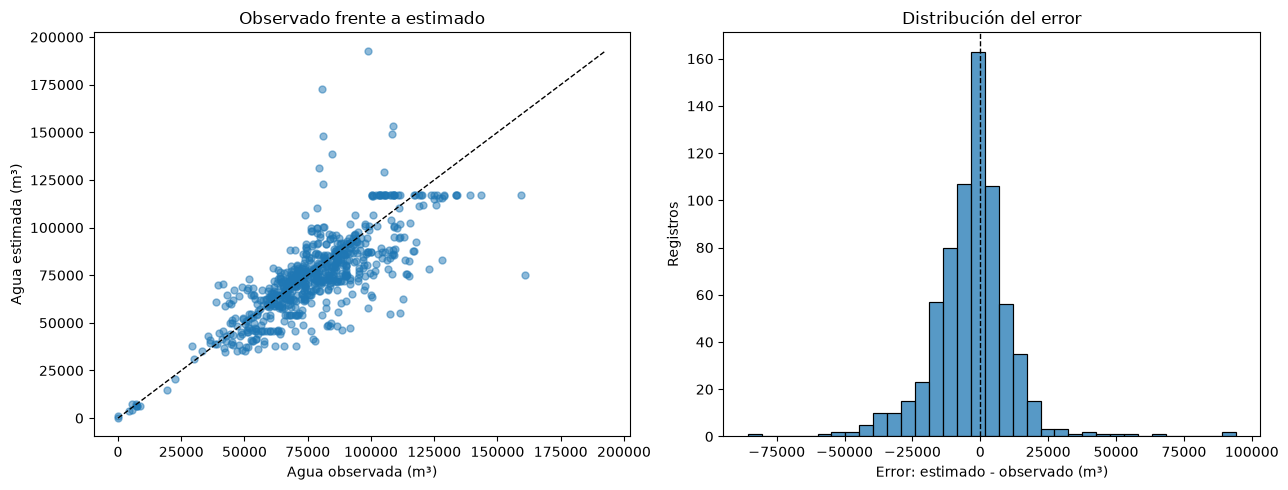

,importancia
num__cantidad_fracturas,0.884
num__longitud_rama_horizontal_m,0.098
cat__tipo_terminacion_Tapón disparo,0.009
cat__tipo_terminacion_Punzado,0.002
cat__formacion_productiva_vaca muerta,0.002
cat__formacion_productiva_lajas,0.001
cat__tipo_terminacion_Camisas y punzados,0.001
cat__subtipo_reservorio_SHALE,0.001
cat__subtipo_reservorio_TIGHT,0.001
cat__tipo_terminacion_Camisas deslizables,0.000


Las importancias describen el uso de variables por el modelo; no prueban causalidad.


In [4]:
def calcular_metricas(nombre, real, pred):
	return {
		"modelo": nombre,
		"MAE_m3": mean_absolute_error(real, pred),
		"RMSE_m3": np.sqrt(mean_squared_error(real, pred)),
		"MedAE_m3": median_absolute_error(real, pred),
		"R2": r2_score(real, pred),
	}


metricas = pd.DataFrame(
	[
		calcular_metricas("Referencia: mediana", y_test, pred_referencia),
		calcular_metricas("Random Forest", y_test, pred_modelo),
	]
)
display(metricas.round(3))

mae_ref = metricas.loc[metricas["modelo"].eq("Referencia: mediana"), "MAE_m3"].iloc[0]
mae_modelo = metricas.loc[metricas["modelo"].eq("Random Forest"), "MAE_m3"].iloc[0]
mejora = 100 * (mae_ref - mae_modelo) / mae_ref
decision = "mejora la referencia" if mejora > 0 else "no mejora la referencia"
print(f"Decisión preliminar: el Random Forest {decision} en MAE ({mejora:.1f}%).")

resultados_test = test[["id_base_fractura_adjiv", "idpozo", "fecha_inicio_fractura"]].copy()
resultados_test["agua_observada_m3"] = y_test.to_numpy()
resultados_test["agua_estimada_m3"] = pred_modelo
resultados_test["error_m3"] = resultados_test["agua_estimada_m3"] - resultados_test["agua_observada_m3"]
resultados_test["error_absoluto_m3"] = resultados_test["error_m3"].abs()
display(resultados_test.nlargest(10, "error_absoluto_m3").round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred_modelo, alpha=0.5, s=25)
limite = max(float(y_test.max()), float(pred_modelo.max()))
axes[0].plot([0, limite], [0, limite], "--", color="black", linewidth=1)
axes[0].set(title="Observado frente a estimado", xlabel="Agua observada (m³)", ylabel="Agua estimada (m³)")

sns.histplot(resultados_test["error_m3"], bins=35, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(title="Distribución del error", xlabel="Error: estimado - observado (m³)", ylabel="Registros")
plt.tight_layout()
plt.show()

nombres = modelo.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(modelo.named_steps["regresor"].feature_importances_, index=nombres, name="importancia").sort_values(ascending=False)
display(importancias.head(12).to_frame().round(3))
print("Las importancias describen el uso de variables por el modelo; no prueban causalidad.")


### Interpretación de la evaluación

### Interpretación de la evaluación

El Random Forest obtiene un **MAE de 10.186,2 m³**, frente a **71.811,9 m³** de la referencia basada en la mediana: reduce el error absoluto promedio en **85,8 %**. El error mediano absoluto (MedAE) se sitúa en **7.099,5 m³**, por lo que en al menos la mitad de los casos el desacierto es acotado. El **R² de 0,516** indica que el modelo explica aproximadamente el 51,6 % de la variabilidad observada en el conjunto de prueba; queda una parte importante sin explicar. El R² altamente negativo de la referencia (-10,942) muestra que la mediana histórica se adapta muy mal al período evaluado.

El RMSE del modelo (**15.098,6 m³**) es mayor que su MAE, lo que señala que existen algunos desaciertos o errores grandes que reciben mayor penalización. La tabla de los mayores errores absolutos permite identificar esos casos concretos: el mayor error alcanza una sobreestimación de unos **94.066,5 m³**, y aparecen tanto sobreestimaciones como subestimaciones significativas que superan los **85.000 m³**. Estos registros forman una lista específica de operaciones para revisar detalladamente.

**Gráfico observado frente a estimado.** La línea punteada representa una predicción perfecta. La mayoría de los puntos sigue una tendencia cercana a esa diagonal, especialmente en el rango medio. Sin embargo, la dispersión aumenta para volúmenes altos y se aprecian limitaciones típicas de los modelos basados en árboles que asignan estimaciones similares en ciertos rangos y no extrapolan con facilidad fuera de los patrones aprendidos.

**Gráfico de errores.** La distribución se concentra alrededor de cero, sin un sesgo global extremo. Aun así, presenta colas hacia ambos lados debido a las estimaciones con mayor desvío. Un error positivo significa que el modelo estimó más agua que la observada; uno negativo significa que subestimó.

**Importancia de variables.** `cantidad_fracturas` concentra la gran mayoría de la importancia calculada, seguida por `longitud_rama_horizontal_m`. Las categorías restantes aportan una proporción menor. Estas cifras reflejan cómo el bosque resolvió sus divisiones en este conjunto y pueden estar afectadas por la correlación operacional entre la longitud y las etapas; no miden un impacto causal directo.

**Conclusión de evaluación.** El modelo supera con claridad la referencia y permite avanzar de forma sólida hacia la implementación. La siguiente iteración incorporará una revisión específica de valores extremos, errores por rango de volumen y formación, y la comparación con operaciones semejantes para dar más contexto a cada estimación.